# Practice effect — distance to cluster medoids

Does practice make players' attempts more prototypical? Every panel reads
`output_data/practice/` (written by `run-practice-distances` and `run-practice-models`);
nothing is refitted here and `mario.scenes` is never opened.

Two measures, kept apart because they answer different questions:

* **`d_own`** — Fréchet distance to the medoid of the attempt's *own* cluster, one
  series per subject × scene × cluster: *when you use this strategy, do you execute it
  more consistently?*
* **`d_nearest_norm`** — distance to the *nearest* medoid (clusters of ≥ 3 members),
  divided by that cluster's spread, one series per subject × scene: *is behaviour
  becoming prototypical of some strategy?* 1.0 = a typical member.

Every measure has a leave-subject-out twin (`_loso`): the medoids are searched among
the *other* subjects, so a late-practice-dominated cluster cannot pull its own
attempts' distances down by construction.

The models are fitted **one subject at a time**: five subjects are too few to
estimate a between-subject variance, so the claim is about these five players,
replicated five times. `d_nearest_norm_loso` is the primary outcome.

In [1]:
import json
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

OUTPUT_DATA_DIR = Path(os.environ["OUTPUT_DATA_DIR"])
PRACTICE_DIR = OUTPUT_DATA_DIR / "practice"

sys.path.insert(0, str(Path("__file__").resolve().parent.parent))
from analysis.practice import load_attempts
from analysis.trace_plots import CLUSTER_COLORS, OTHER_COLOR, SUBJECT_COLORS, N_DIRECT_CLUSTERS

attempts = load_attempts(OUTPUT_DATA_DIR)
curves = pd.read_csv(PRACTICE_DIR / "curves.csv", dtype={"subject": str})
mixed = json.loads((PRACTICE_DIR / "mixed.json").read_text())
switching = json.loads((PRACTICE_DIR / "switching.json").read_text())

UNITS = {"d_own": "Fréchet distance to own medoid (px)",
         "d_nearest_norm": "distance to nearest medoid / its spread"}
RAW, LOSO = CLUSTER_COLORS[0], CLUSTER_COLORS[1]
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e6e5df", "grid.linewidth": 0.6})
print(f"{len(attempts)} attempts over {attempts['scene'].nunique()} scenes")

55094 attempts over 300 scenes


## 1. One participant, one scene

The richest subject × scene series. Top: `d_own`, each point coloured by its cluster
(colour slot by whole-scene cluster size, as everywhere else), with a rolling median
for each cluster the subject used >= 10 times, as a visual guide — the fitted curves are in `curves.csv`. Middle:
`d_nearest_norm` over every attempt. Bottom: which cluster each attempt used, so a
strategy switch is visible on its own rather than folded into a distance.
Medoid attempts (distance 0 by definition) are left out.

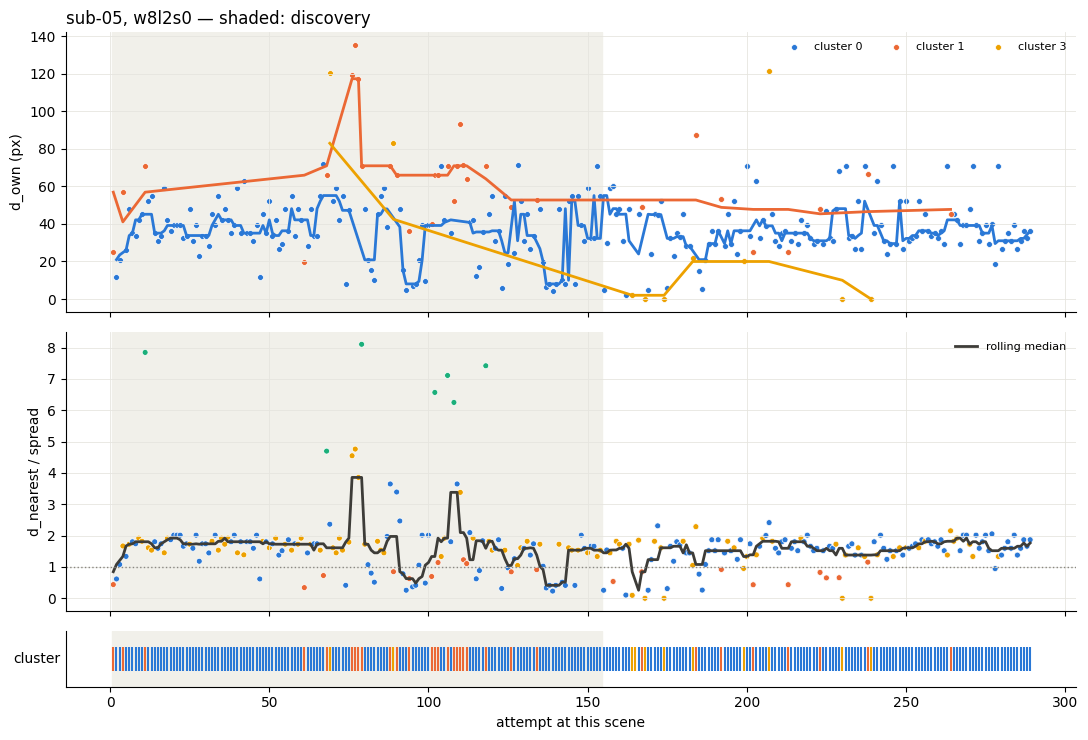

In [2]:
fit = attempts[~attempts["is_medoid"]]
per_cluster = fit.groupby(["scene", "subject", "cluster"]).size()
rich = per_cluster[per_cluster >= 10].groupby(["scene", "subject"]).size()
scene, subject = fit[fit.set_index(["scene", "subject"]).index.isin(rich[rich >= 2].index)] \
    .groupby(["scene", "subject"]).size().idxmax()

scene_df = attempts[attempts["scene"] == scene]
rank = scene_df["cluster"].value_counts().index.tolist()
color = {k: CLUSTER_COLORS[r] if r < N_DIRECT_CLUSTERS else OTHER_COLOR for r, k in enumerate(rank)}
s = scene_df[scene_df["subject"] == subject].sort_values("attempt")
sf = s[~s["is_medoid"]]
boundary = s.loc[s["phase"] == "practice", "attempt"].min()

fig, axes = plt.subplots(3, 1, figsize=(11, 7.5), sharex=True,
                         gridspec_kw={"height_ratios": [3, 3, 0.6]})
for k, g in sf.groupby("cluster"):
    axes[0].scatter(g["attempt"], g["d_own"], s=18, color=color[k], label=f"cluster {k}",
                    edgecolor="white", linewidth=0.5)
    if len(g) >= 10:   # same floor as the per-series fits; sparser clusters get points only
        axes[0].plot(g["attempt"], g["d_own"].rolling(5, center=True, min_periods=3).median(),
                     color=color[k], linewidth=2)
axes[0].set_ylabel("d_own (px)")
axes[0].legend(ncol=4, fontsize=8, frameon=False, loc="upper right")

axes[1].scatter(sf["attempt"], sf["d_nearest_norm"], s=18, color=[color[k] for k in sf["nearest_cluster"]],
                edgecolor="white", linewidth=0.5)
axes[1].plot(sf["attempt"], sf["d_nearest_norm"].rolling(7, center=True, min_periods=3).median(),
             color="#3d3c38", linewidth=2, label="rolling median")
axes[1].axhline(1.0, color="#898781", linewidth=1, linestyle=":")
axes[1].set_ylabel("d_nearest / spread")
axes[1].legend(frameon=False, fontsize=8, loc="upper right")

axes[2].scatter(s["attempt"], np.zeros(len(s)), marker="|", s=300, color=[color[k] for k in s["cluster"]])
axes[2].set_yticks([]); axes[2].grid(False)
axes[2].set_ylabel("cluster", rotation=0, ha="right", va="center")
axes[2].set_xlabel("attempt at this scene")
for ax in axes:
    if pd.notna(boundary):
        ax.axvspan(s["attempt"].min() - 0.5, boundary - 0.5, color="#f1f0ea", zorder=0)
axes[0].set_title(f"sub-{subject}, {scene} — shaded: discovery", loc="left")
fig.tight_layout()
fig.savefig(PRACTICE_DIR / "figure_practice_example.png", dpi=150)

## The main analysis, scene scale (lme4)

`log(d) ~ log(attempt) + (1 + log(attempt) | level) + (1 + log(attempt) | level:scene)`, one
model per subject, fitted in R by `invoke run-practice-lme4` (`lme4.json`). Scenes are nested
in levels because a level's scenes are played back to back. Left: the practice slope with its
95% CI (profile likelihood, Wald where the profile failed), raw medoids against
leave-subject-out, with the Benjamini-Hochberg (BH-FDR) adjusted p-value for the primary measure across the five
subjects. Right: each subject's fitted curve for the primary measure — the average scene and
level — back-transformed. The figures above are the scene-only statsmodels model, kept as a
robustness check.

,subject,b,ci,ci_method,p,p_bh
0,01,-0.0107,"[-0.0328641360951353, 0.0110689625550302]",profile,0.3174,0.3174
1,02,-0.0275,"[-0.0469273326983695, -0.0080358041457145]",wald,0.0056,0.0093
2,03,-0.0365,"[-0.070164903394219, -0.0029951741406675]",profile,0.0257,0.0322
3,05,-0.0660,"[-0.0905449937189489, -0.0433630917851372]",profile,0.0000,0.0000
4,06,-0.0616,"[-0.0858317533236723, -0.0390516677270638]",profile,0.0000,0.0000


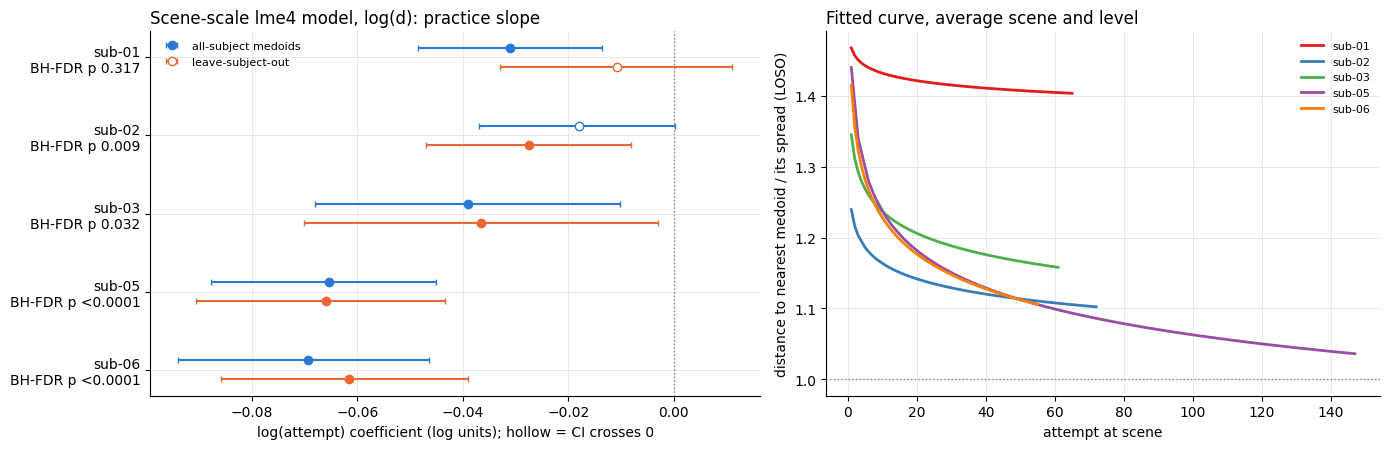

In [3]:
lme4_path = PRACTICE_DIR / "lme4.json"
if not lme4_path.exists():
    print("lme4.json not found - run invoke run-practice-lme4 (needs R with lme4).")
else:
    from analysis.practice import TRANSFORMS
    INVERSE = {k: v[1] for k, v in TRANSFORMS.items()}
    lme4 = json.loads(lme4_path.read_text())
    subjects = lme4["subjects"]
    T = lme4["primary_transform"]
    nested = [f for f in lme4["fits"] if f["model"] == "nested" and f["transform"] == T
              and not f["completed_only"]]
    by = {(f["measure"], f["subject"]): f for f in nested}
    prim = {s: by[(lme4["primary"], s)]["p_wald"] for s in subjects if (lme4["primary"], s) in by}
    order = sorted(prim, key=prim.get)
    from statsmodels.stats.multitest import multipletests
    bh = dict(zip(order, multipletests([prim[s] for s in order], method="fdr_bh")[1]))   # Benjamini-Hochberg

    fig, (ax, axc) = plt.subplots(1, 2, figsize=(14, 4.6), gridspec_kw={"width_ratios": [1.1, 1]})
    base = lme4["primary"].replace("_loso", "")
    for off, (col, c, lbl) in zip((-0.12, 0.12), ((base, RAW, "all-subject medoids"),
                                                  (lme4["primary"], LOSO, "leave-subject-out"))):
        for i, s in enumerate(subjects):
            f = by.get((col, s))
            if f is None:
                continue
            b, (lo, hi) = f["b"], f["ci"]
            clear = hi < 0 or lo > 0
            ax.errorbar(b, i + off, xerr=[[b - lo], [hi - b]], fmt="o", color=c, ms=6, capsize=2,
                        mfc=c if clear else "white", label=lbl if i == 0 else None)
    ax.axvline(0, color="#898781", lw=1, ls=":")
    ax.set_yticks(range(len(subjects)),
                  [f"sub-{s}\nBH-FDR p {bh[s]:.3f}" if bh.get(s, 1) >= 1e-4 else f"sub-{s}\nBH-FDR p <0.0001"
                   for s in subjects])
    ax.invert_yaxis()
    ax.set_xlabel(f"log(attempt) coefficient ({T} units); hollow = CI crosses 0")
    ax.set_title(f"Scene-scale lme4 model, {T}(d): practice slope", loc="left")
    ax.legend(frameon=False, fontsize=8)
    inv = INVERSE[T]
    for i, s in enumerate(subjects):
        f = by.get((lme4["primary"], s))
        if f:
            axc.plot(f["curve"]["attempt"], inv(np.asarray(f["curve"]["y"])), color=SUBJECT_COLORS[i],
                     lw=2, label=f"sub-{s}")
    axc.axhline(1.0, color="#898781", lw=1, ls=":")
    axc.set_xlabel("attempt at scene")
    axc.set_ylabel(UNITS["d_nearest_norm"] + " (LOSO)")
    axc.set_title("Fitted curve, average scene and level", loc="left")
    axc.legend(frameon=False, fontsize=8)
    fig.tight_layout()
    fig.savefig(PRACTICE_DIR / "figure_practice_lme4.png", dpi=150)
    display(pd.DataFrame([{"subject": s, "b": by[(lme4["primary"], s)]["b"],
                           "ci": by[(lme4["primary"], s)]["ci"], "ci_method": by[(lme4["primary"], s)]["ci_method"],
                           "p": prim[s], "p_bh": bh[s]} for s in subjects]).round(4))

## Does the fit follow the data?

The curves above are drawn alone, so they can't show whether they follow the attempts they
were fitted on. Here each subject's fixed-effect curve (black) is drawn over its own data.
The rows are exactly the fitted rows: `fit_check_data` builds them with the same frame
functions, and its `n_obs` matches the fit's. Primary transform, all attempts. Both axes are on a
**log scale**, labelled in ordinary units (attempt number, distance). There, the model is a straight line, so a bend in the bins is what a wrong
functional form would look like.

Each model gets two rows, and the second is the real check.

* **Pooled** (rows 1 and 3): every attempt as a faint grey point (a seeded sample of 1,500
  per panel), and the data binned by attempt (coloured; 95% interval). Attempts 1-5 get a
  bin each, then log-spaced bins up to the 95th-percentile attempt, where the curve stops.
  The bins are geometric means (the mean of `log(d)`, back-transformed). That's the same
  quantity the curve is, so skew alone can't put them above it.
* **Partial residuals** (rows 2 and 4): the same bins over the
  [ggeffects](https://strengejacke.github.io/ggeffects/) partial residuals, which is the
  standard picture of a mixed-model fit against its data. Each attempt is the fixed-effect
  prediction plus its residual after its own level's, scene's and route's intercept and
  slope are taken out. These come from `invoke run-practice-lme4-effects`, which refits
  every stored lme4 fit and checks it reproduces the stored coefficients.

Why the second row is needed: the fixed slope is a *within*-unit slope. The pooled bins
also carry *between*-unit differences, and in the route model those are large. A route that
ends up reused 20+ times is already about 30% tighter on its first use than one dropped
after a few (sub-01: mean `log(d)` at first use 3.35 vs 3.75). So the late pooled bins hold
only tight routes and fall well below the line, even though the model is right. For the scene
model the two rows come out almost identical (bins within 2-5%; 15% at one bin for sub-05):
scenes differ little next to the attempt-to-attempt noise (sub-01: scene intercept variance
0.13 against a residual variance of 0.38), and the scenes played longest are not
systematically easier or harder, so there the raw data was already a fair check. The number
under each pooled last bin is how many scenes it still holds.

The error bars treat every attempt as independent. Attempts at one scene are not, so the
bars are narrower than an honest interval: read them as "where the bin sits", not as a test.

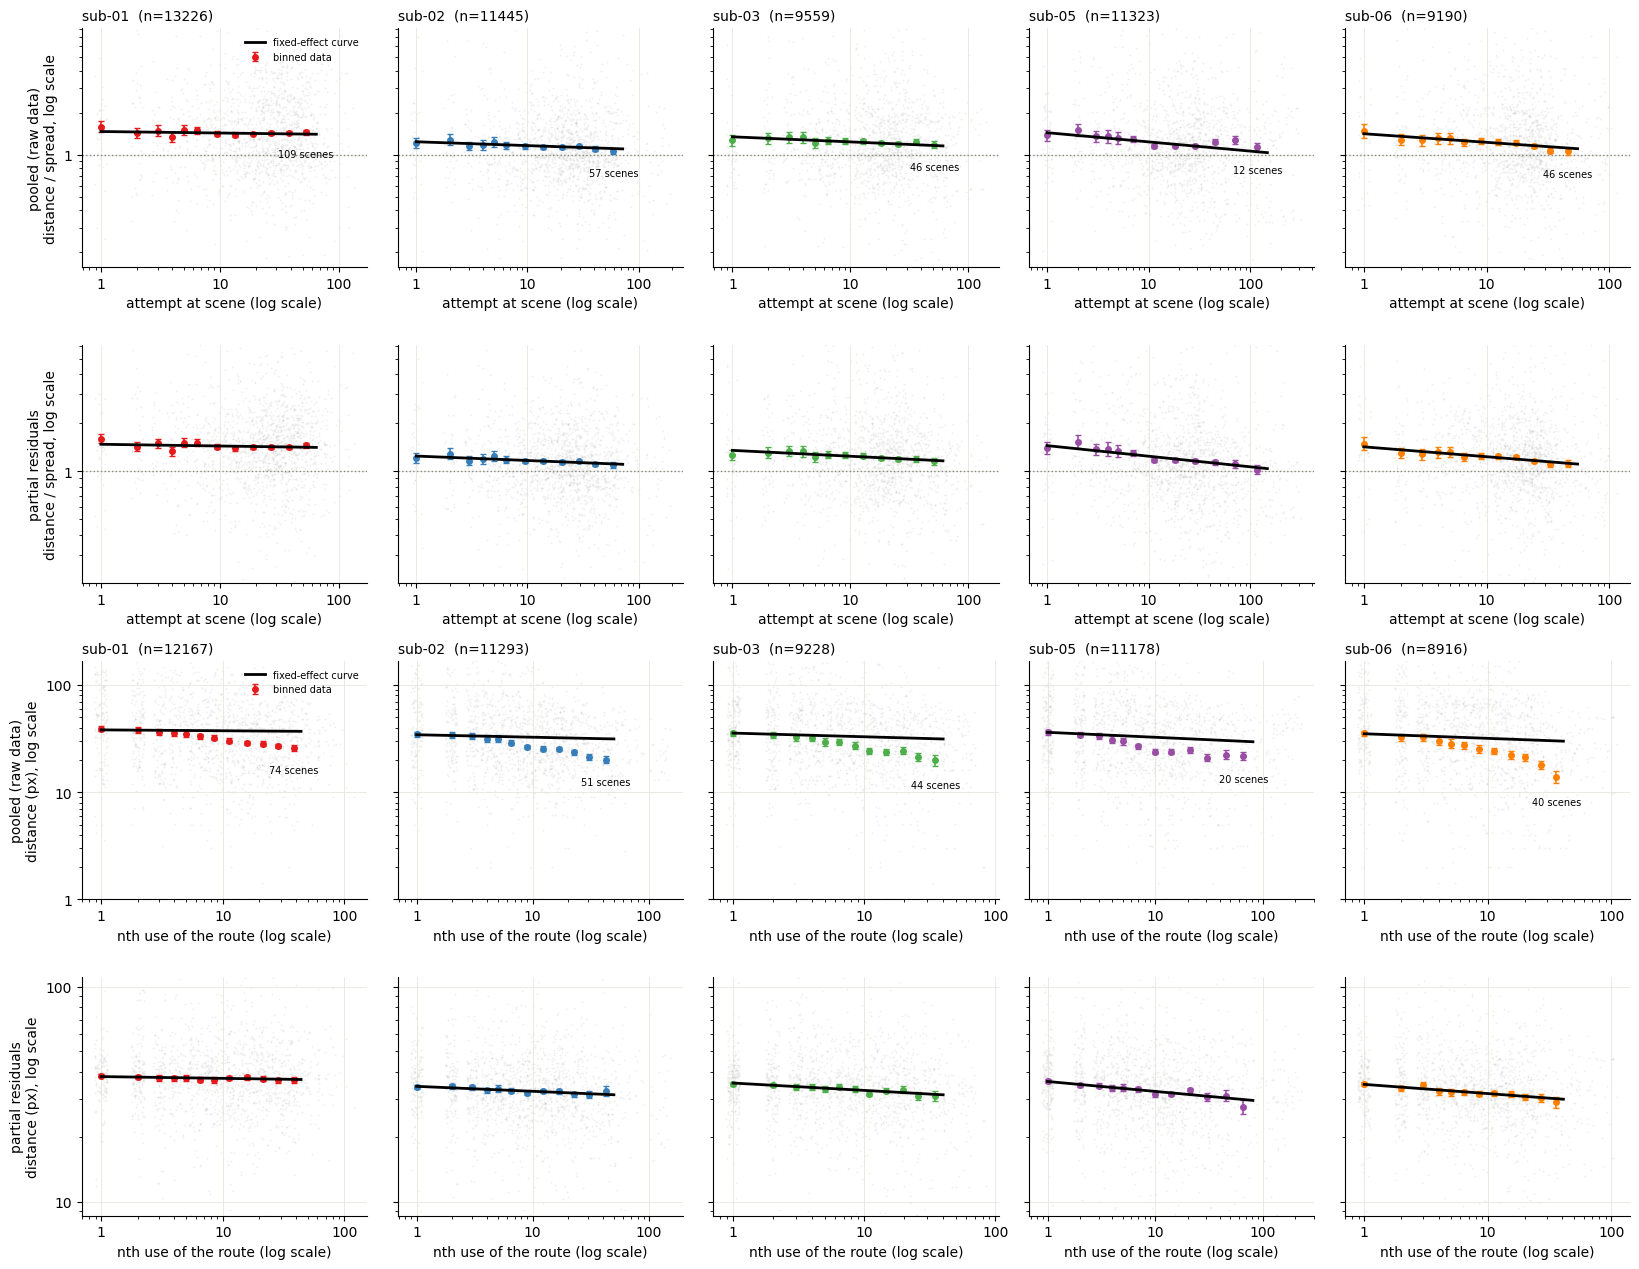

In [4]:
from matplotlib.ticker import FuncFormatter, NullFormatter

from analysis.practice import TRANSFORMS, fit_check_data, fit_id, load_effects

lme4 = json.loads((PRACTICE_DIR / "lme4.json").read_text()) if (PRACTICE_DIR / "lme4.json").exists() else None
route = json.loads((PRACTICE_DIR / "lme4_route.json").read_text()) if (PRACTICE_DIR / "lme4_route.json").exists() else None
effects = load_effects(OUTPUT_DATA_DIR)
if effects is None:
    print("No lme4 effects - run invoke run-practice-lme4-effects (needs R with ggeffects); "
          "drawing the pooled rows only.")
MODELS = [(lme4, "nested", "attempt at scene (log scale)", "distance / spread"),
          (route, "route", "nth use of the route (log scale)", "distance (px)")]
MODELS = [m for m in MODELS if m[0] is not None]


def fit_panel(ax, data, fit, inv, color, partial):
    col = 2 if partial else 1
    pts = np.asarray([p for p in data["points"] if p[col] is not None], dtype=float)
    jitter = np.exp(np.random.default_rng(0).uniform(-0.12, 0.12, len(pts)))
    ax.scatter(pts[:, 0] * jitter, pts[:, col], s=2, color="#898781", alpha=0.12, lw=0, rasterized=True)
    b = pd.DataFrame(data["partial_bins" if partial else "bins"])
    ax.errorbar(b["x"], b["mean"], yerr=[b["mean"] - b["lo"], b["hi"] - b["mean"]], fmt="o", color=color,
                ms=4, capsize=2, lw=1.2, zorder=3, label="binned data")
    ax.plot(fit["curve"]["attempt"], inv(np.asarray(fit["curve"]["y"])), color="black", lw=2,
            zorder=4, label="fixed-effect curve")
    if not partial:
        ax.annotate(f"{b['n_scenes'].iloc[-1]} scenes", (b["x"].iloc[-1], b["lo"].iloc[-1]), xytext=(0, -10),
                    textcoords="offset points", ha="center", va="top", fontsize=7)
    ax.set_xscale("log")
    ax.set_yscale("log")
    for axis in (ax.xaxis, ax.yaxis):
        axis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:g}"))
        axis.set_minor_formatter(NullFormatter())
    ax.set_ylim(*np.quantile(pts[:, col], [0.01, 0.99]))


if not MODELS:
    print("No lme4 fits found - run invoke run-practice-lme4 (needs R with lme4).")
else:
    subjects = MODELS[0][0]["subjects"]
    per_model = 2 if effects is not None else 1
    fig, axes = plt.subplots(per_model * len(MODELS), len(subjects),
                             figsize=(3.3 * len(subjects), 3.2 * per_model * len(MODELS)),
                             squeeze=False, sharey="row")
    for k, (src, model, xlabel, ylabel) in enumerate(MODELS):
        T, measure = src["primary_transform"], src["primary"]
        for i, s in enumerate(subjects):
            fit = next((f for f in src["fits"] if f["model"] == model and f["measure"] == measure
                        and f["subject"] == s and f["transform"] == T and not f["completed_only"]), None)
            rows = [per_model * k + j for j in range(per_model)]
            if fit is None:
                for r in rows:
                    axes[r, i].set_visible(False)
                continue
            eff = None
            if effects is not None:
                eff = effects[0][effects[0]["fid"] == fit_id(model, measure, T, False, s)]
            data = fit_check_data(attempts, model, measure, s, T, effects=eff)
            for partial, r in zip((False, True), rows):
                ax = axes[r, i]
                fit_panel(ax, data, fit, TRANSFORMS[T][1], SUBJECT_COLORS[i], partial)
                if model == "nested":
                    ax.axhline(1.0, color="#898781", lw=1, ls=":")
                ax.set_xlabel(xlabel)
            axes[rows[0], i].set_title(f"sub-{s}  (n={data['n_obs']})", loc="left", fontsize=10)
        axes[per_model * k, 0].set_ylabel(f"pooled (raw data)\n{ylabel}, log scale")
        if effects is not None:
            axes[per_model * k + 1, 0].set_ylabel(f"partial residuals\n{ylabel}, log scale")
        axes[per_model * k, 0].legend(frameon=False, fontsize=7, loc="upper right")
    fig.tight_layout()
    fig.savefig(PRACTICE_DIR / "figure_practice_lme4_data.png", dpi=150)

### One line per scene, and per route

The figure above summarises the data across scenes. This one shows the model **scene by
scene**, which is the usual "spaghetti" view of a mixed model. For each subject, the six
scenes they played most: every attempt as a point, with that scene's own fitted line, which
is the fixed effect plus its level's and scene's random intercept and slope. Rows: subjects.
The dashed grey line is the fixed-effect (average-scene) line, for reference.

* **Scene-scale model** (`figure_practice_lme4_spaghetti_scene.png`): one line per scene.
* **Route-scale model** (`figure_practice_lme4_spaghetti_route.png`): one line per
  **route** used at that scene, since the route model gives every route its own intercept
  and slope. Points and lines are coloured by route, with slots by whole-scene route size as
  everywhere else. Each line stops at that route's last use.

The lines come from `run-practice-lme4-effects` (the BLUPs of the stored fits), and
rebuilding them reproduces lme4's own fitted values. A line that misses its points is
worth a look; one that is just short or flat usually means the route was used only a few
times, and the model pulled it toward the average.

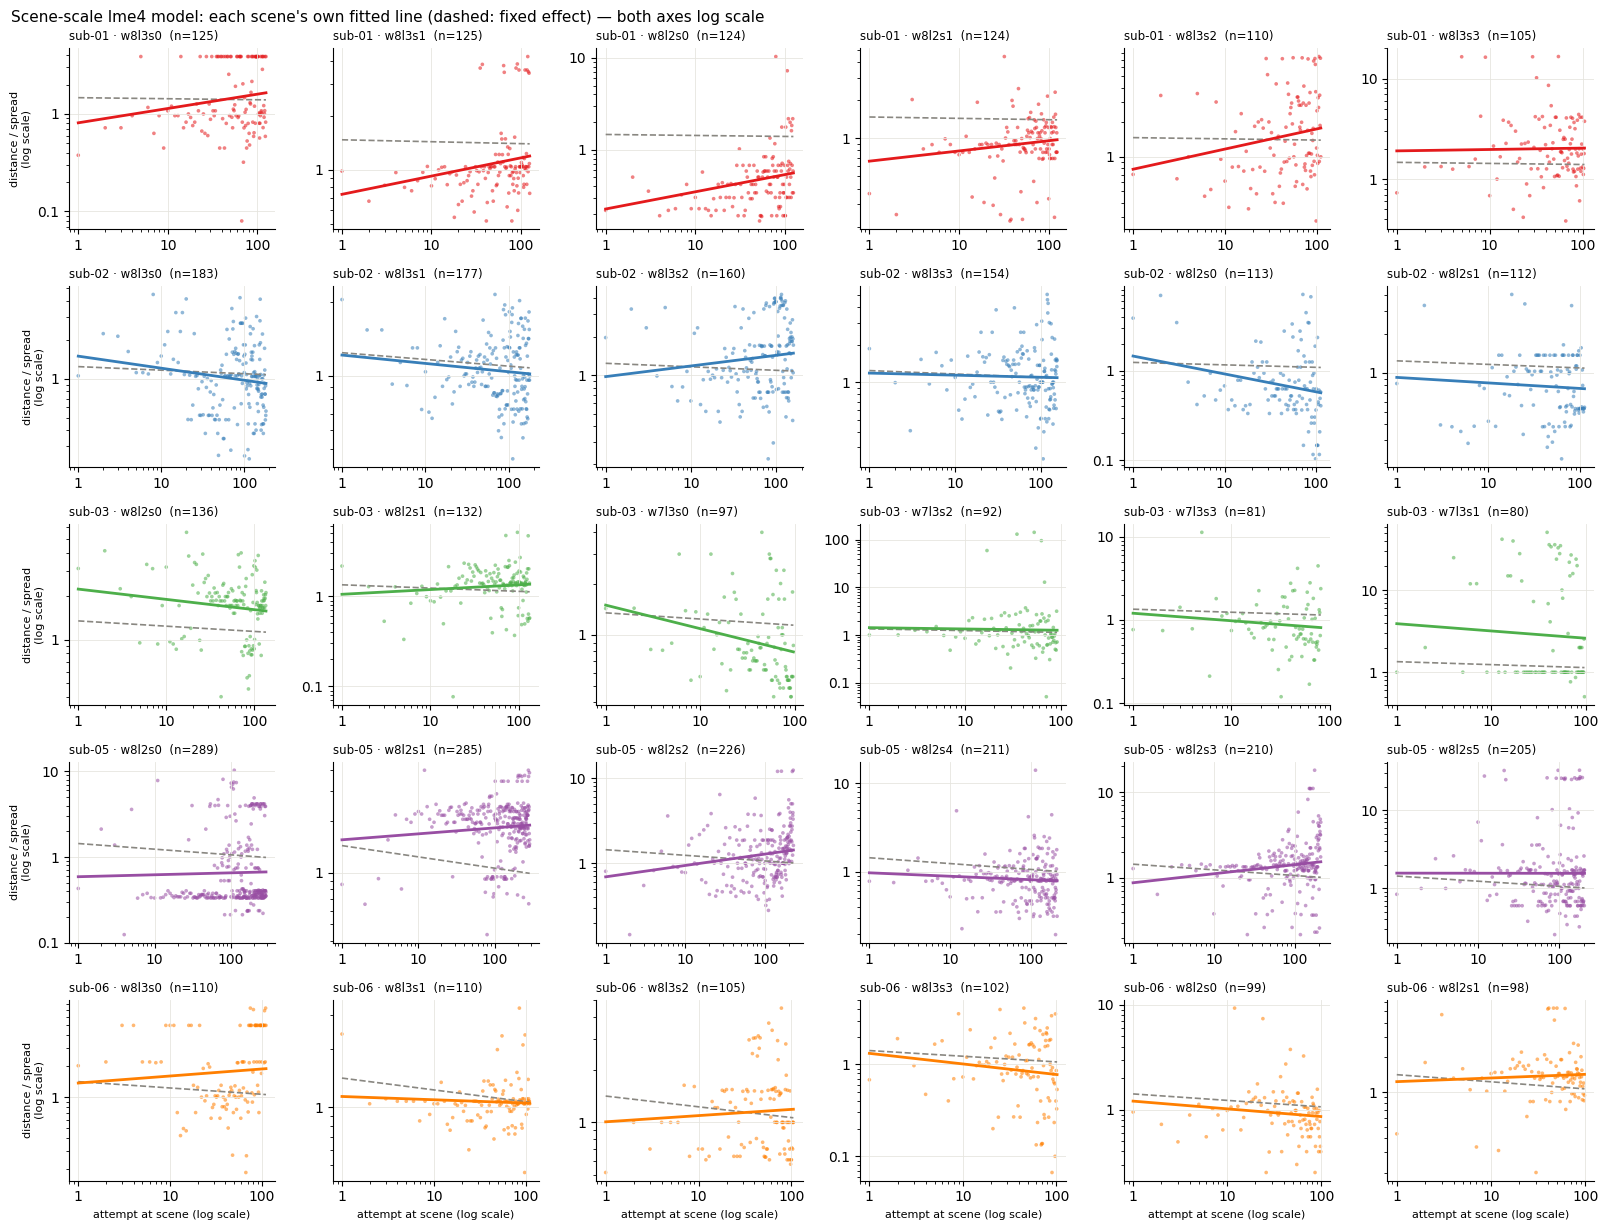

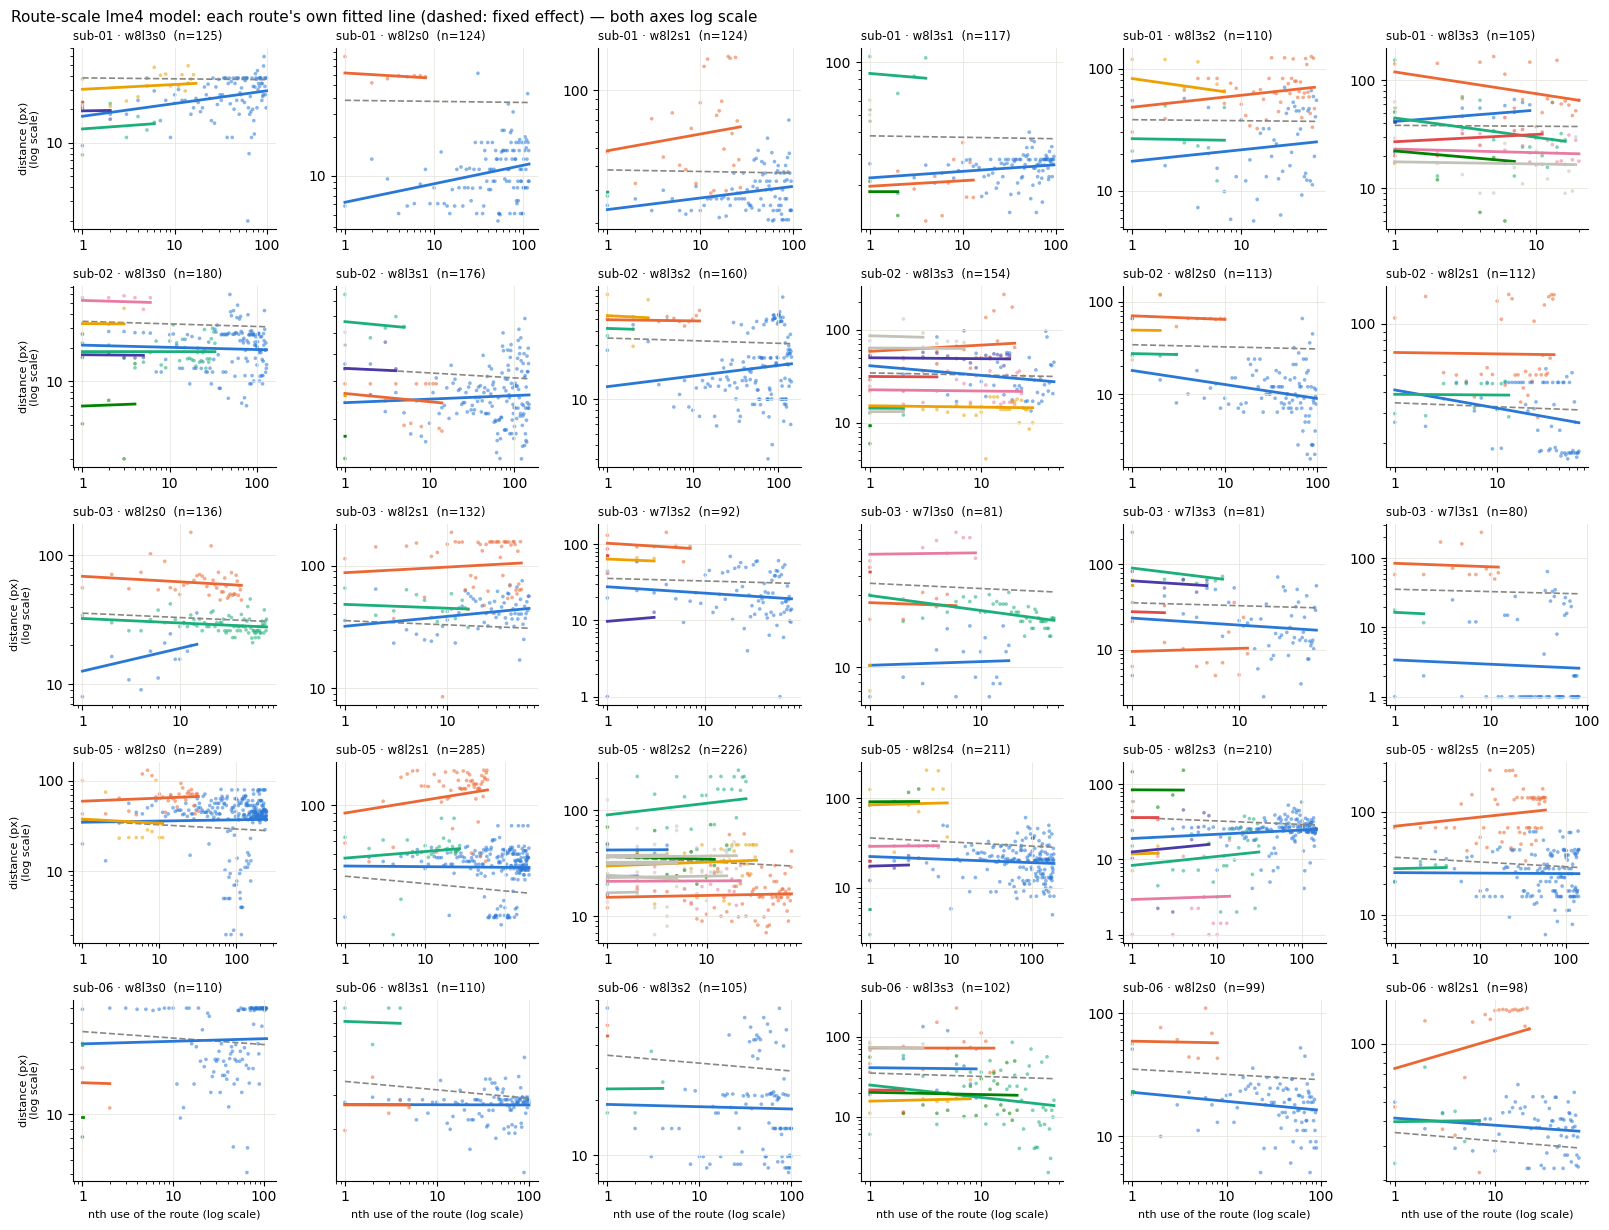

In [5]:
from matplotlib.ticker import FuncFormatter, NullFormatter

from analysis.practice import spaghetti_data

PLAIN = FuncFormatter(lambda v, _: f"{v:g}")

if effects is None or not MODELS:
    print("No lme4 effects - run invoke run-practice-lme4-effects (needs R with ggeffects).")
else:
    partial, ranef, fixef = effects
    for src, model, xlabel, ylabel in MODELS:
        T, measure = src["primary_transform"], src["primary"]
        inv = TRANSFORMS[T][1]
        subjects = src["subjects"]
        sp = {s: spaghetti_data(partial, ranef, fixef, fit_id(model, measure, T, False, s)) for s in subjects}
        ncol = max(len(v["scenes"]) for v in sp.values())
        fig, axes = plt.subplots(len(subjects), ncol, figsize=(2.7 * ncol, 2.5 * len(subjects)), squeeze=False)
        for i, s in enumerate(subjects):
            fe = sp[s]["fixed"]
            for j in range(ncol):
                ax = axes[i, j]
                items = list(sp[s]["scenes"].items())
                if j >= len(items):
                    ax.set_visible(False)
                    continue
                scene, v = items[j]
                pts = np.asarray(v["points"], dtype=float)
                if model == "route":
                    rank = attempts[(attempts["scene"] == scene) & (attempts["cluster"] >= 0)]["cluster"] \
                        .value_counts().index.tolist()
                    colour = {c: CLUSTER_COLORS[r] if r < N_DIRECT_CLUSTERS else OTHER_COLOR
                              for r, c in enumerate(rank)}
                else:
                    colour = {-1: SUBJECT_COLORS[i]}
                ax.scatter(pts[:, 0], pts[:, 1], s=7, lw=0, alpha=0.55,
                           c=[colour.get(int(r), OTHER_COLOR) for r in pts[:, 2]])
                xs = np.geomspace(1, pts[:, 0].max(), 50)
                ax.plot(xs, inv(fe["a"] + fe["b"] * np.log(xs)), color="#898781", lw=1.2, ls="--")
                for line in v["lines"]:
                    xl = np.geomspace(1, max(line["x1"], 1.01), 30)
                    ax.plot(xl, inv(line["a"] + line["b"] * np.log(xl)), lw=2,
                            color=colour.get(line["route"], OTHER_COLOR))
                ax.set_xscale("log")
                ax.set_yscale("log")
                for axis in (ax.xaxis, ax.yaxis):
                    axis.set_major_formatter(PLAIN)
                    axis.set_minor_formatter(NullFormatter())
                ax.set_title(f"sub-{s} · {scene}  (n={v['n']})", loc="left", fontsize=8.5)
                if i == len(subjects) - 1:
                    ax.set_xlabel(xlabel, fontsize=8)
            axes[i, 0].set_ylabel(f"{ylabel}\n(log scale)", fontsize=8)
        fig.suptitle(f"{'Route' if model == 'route' else 'Scene'}-scale lme4 model: each "
                     f"{'route' if model == 'route' else 'scene'}'s own fitted line "
                     f"(dashed: fixed effect) — both axes log scale", x=0.01, ha="left", fontsize=11)
        fig.tight_layout()
        name = "route" if model == "route" else "scene"
        fig.savefig(PRACTICE_DIR / f"figure_practice_lme4_spaghetti_{name}.png", dpi=130)

### Scene effects or route effects, and is the decrease curved?

The pooled row of the route-scale figure falls much more steeply than the route model's line.
`run-practice-route-checks` fits that same data (own-route distance against nth use,
leave-subject-out medoids, `log(d)`, all attempts) four ways, each removing more. Every line is
the fixed-effect slope: the trend left once the named differences are taken out.

* **nothing removed** (grey): a plain least-squares line through every attempt, no random
  effects, the trend the pooled bins show. Its CI treats attempts as independent, so it is far
  too narrow and is not tested.
* **scene & level differences removed** (blue): each level and scene gets its own intercept and
  slope (random effects), and routes are not separated. Does the pooled decrease survive scenes
  that are easier or played more?
* **+ route baselines removed** (green): each route also gets its own intercept only, so routes
  may differ in how tight they are but improve at the same rate. This removes structure (some
  routes are simply tighter); the slope left is change along a route.
* **scene, level & route differences removed** (orange): the route-scale model itself. Each
  route gets its own intercept and slope, so it is also allowed its own rate of improvement.

Each is fitted as a straight line on log-log axes (solid) and with a `log(use)^2` term (dashed).
The curvature term is a fixed effect only; scenes and routes keep their own straight slope.
The bins are the pooled bins from the figure above. The scene- and route-corrected lines are
average-scene (and average-route) lines, so the pooled bins need not sit on them.

The second table judges each **whole polynomial**, not its single terms (a quadratic's two
coefficients can trade off): the total change from use 1 to the end of the range under the
straight and the quadratic shape, and a joint Wald test that every practice term is zero
(2 df for the quadratic). The pooled model's p values treat attempts as independent and
are not corrected.

correction,pooled %/doubling,scene %/doubling,route_int %/doubling,route %/doubling,pooled dAIC quad-lin,scene dAIC quad-lin,route_int dAIC quad-lin,route dAIC quad-lin,scene curvature p (BH),route_int curvature p (BH),route curvature p (BH)
subject,,,,,,,,,,,
01,-7.8,-4.3,-0.2,-0.6,0.4,1.4,-2.9,-3.0,0.455,0.135,0.124
02,-9.6,-6.0,-1.5,-1.6,-2.9,1.4,1.9,2.0,0.455,0.922,0.877
03,-10.5,-9.7,-2.2,-2.3,-2.6,-1.6,-0.5,0.0,0.146,0.279,0.404
05,-7.0,-8.7,-3.1,-3.1,-82.7,-0.6,2.0,1.7,0.173,0.922,0.863
06,-12.0,-7.9,-2.8,-2.9,1.4,-4.4,1.8,1.8,0.056,0.922,0.863


,pooled straight %,pooled quadratic %,pooled joint p (BH),scene straight %,scene quadratic %,scene joint p (BH),route_int straight %,route_int quadratic %,route_int joint p (BH),route straight %,route quadratic %,route joint p (BH),end of range (use)
subject,,,,,,,,,,,,,
01,-36.0,-35.0,1.1e-64,-22.0,-21.0,0.0012,-1.0,-0.0,0.08,-3.0,-0.0,0.049,44
02,-44.0,-43.0,6.5e-100,-29.0,-28.0,1.1e-06,-8.0,-9.0,0.021,-9.0,-9.0,0.015,50
03,-45.0,-45.0,2.2e-69,-42.0,-44.0,7e-07,-11.0,-13.0,0.045,-12.0,-14.0,0.024,40
05,-37.0,-37.0,6.6e-68,-44.0,-47.0,8.7e-07,-18.0,-18.0,8.4e-05,-18.0,-17.0,0.00016,81
06,-49.0,-49.0,2.1e-80,-36.0,-32.0,4.3e-12,-14.0,-14.0,0.00025,-15.0,-14.0,0.00021,41


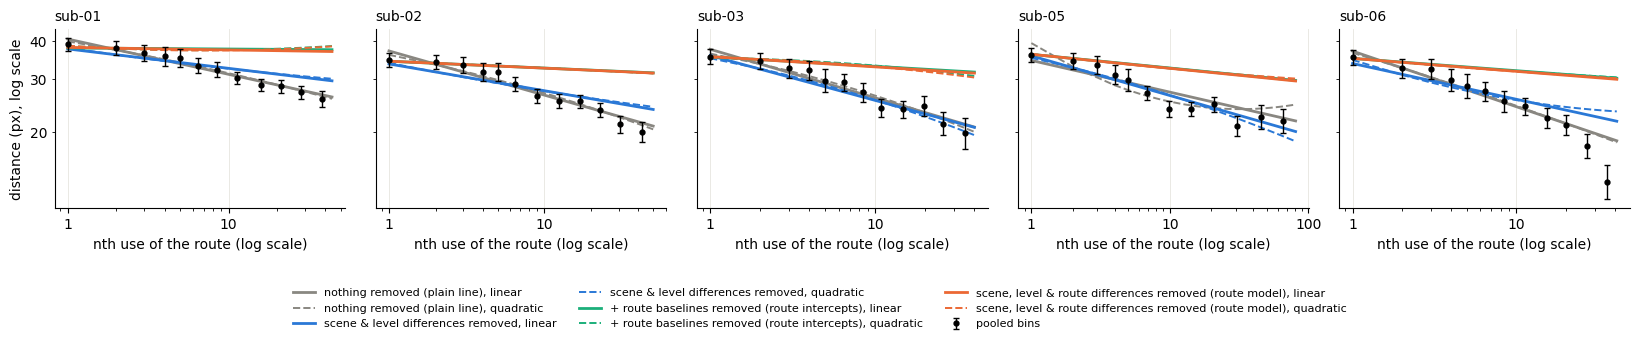

In [6]:
from matplotlib.ticker import FuncFormatter, NullFormatter

from analysis.practice import TRANSFORMS, fit_check_data

checks_path = PRACTICE_DIR / "route_checks.json"
if not checks_path.exists():
    print("No route checks - run invoke run-practice-route-checks (needs R with lme4).")
else:
    checks = json.loads(checks_path.read_text())
    T, measure = checks["primary_transform"], checks["primary"]
    inv = TRANSFORMS[T][1]
    fits = pd.DataFrame(checks["fits"])
    fits = fits[(fits["measure"] == measure) & (fits["transform"] == T) & (fits["completed_only"] == False)]
    CORR = [("pooled", "nothing removed (plain line)", "#898781"),
            ("scene", "scene & level differences removed", CLUSTER_COLORS[0]),
            ("route_int", "+ route baselines removed (route intercepts)", CLUSTER_COLORS[2]),
            ("route", "scene, level & route differences removed (route model)", CLUSTER_COLORS[1])]
    subjects = checks["subjects"]
    fig, axes = plt.subplots(1, len(subjects), figsize=(3.3 * len(subjects), 3.4), squeeze=False, sharey=True)
    ys = []
    for ax, s in zip(axes[0], subjects):
        b = pd.DataFrame(fit_check_data(attempts, "route", measure, s, T)["bins"])
        ax.errorbar(b["x"], b["mean"], yerr=[b["mean"] - b["lo"], b["hi"] - b["mean"]], fmt="o",
                    color="black", ms=3.5, capsize=2, lw=1, zorder=3, label="pooled bins")
        ys += [*b["lo"], *b["hi"]]
        for corr, label, color in CORR:
            for shape, ls in (("linear", "-"), ("quadratic", "--")):
                f = fits[(fits["subject"] == s) & (fits["correction"] == corr) & (fits["shape"] == shape)].iloc[0]
                ys += list(inv(np.asarray(f["curve"]["y"])))
                ax.plot(f["curve"]["use"], inv(np.asarray(f["curve"]["y"])), color=color, ls=ls,
                        lw=2 if shape == "linear" else 1.4, label=f"{label}, {shape}")
        ax.set_xscale("log")
        ax.set_yscale("log")
        for axis in (ax.xaxis, ax.yaxis):
            axis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:g}"))
        ax.xaxis.set_minor_formatter(NullFormatter())
        ax.yaxis.set_minor_formatter(FuncFormatter(lambda v, _: f"{v:g}"))   # the range is under a decade
        ax.set_title(f"sub-{s}", loc="left", fontsize=10)
        ax.set_xlabel("nth use of the route (log scale)")
    axes[0, 0].set_ylabel("distance (px), log scale")
    axes[0, 0].set_ylim(min(ys) * 0.93, max(ys) * 1.07)
    handles, labels = axes[0, 0].get_legend_handles_labels()
    fig.legend(handles, labels, frameon=False, fontsize=8, ncol=3, loc="lower center")
    fig.tight_layout(rect=(0, 0.2, 1, 1))
    fig.savefig(PRACTICE_DIR / "figure_practice_route_checks.png", dpi=150)

    pct = lambda b: (2 ** b - 1) * 100
    lin = fits[fits["shape"] == "linear"].pivot(index="subject", columns="correction", values="b")
    CORR = [x for x in CORR if x[0] in set(fits["correction"])]
    order = [x[0] for x in CORR]
    table = pct(lin[order]).round(1).add_suffix(" %/doubling")
    q = fits[fits["shape"] == "quadratic"].set_index(["subject", "correction"])
    l = fits[fits["shape"] == "linear"].set_index(["subject", "correction"])
    for corr in order:
        table[f"{corr} dAIC quad-lin"] = (q["aic"] - l["aic"]).xs(corr, level="correction").round(1)
    table["scene curvature p (BH)"] = q["lrt_p_bh"].xs("scene", level="correction").round(3)
    for corr in order[2:]:
        table[f"{corr} curvature p (BH)"] = q["lrt_p_bh"].xs(corr, level="correction").round(3)
    display(table)

    # The whole polynomial, not single terms: change from use 1 to the end of the range under
    # each shape (both terms together), and the joint test that every practice term is zero.
    total = lambda f: (np.exp(f["change_end"]) - 1) * 100
    whole = pd.DataFrame(index=lin.index)
    for corr in order:
        whole[f"{corr} straight %"] = total(l.xs(corr, level="correction")).round(0)
        whole[f"{corr} quadratic %"] = total(q.xs(corr, level="correction")).round(0)
        whole[f"{corr} joint p (BH)"] = q["joint_p_bh" if corr != "pooled" else "joint_p"].xs(
            corr, level="correction").map(lambda v: f"{v:.2g}")
    whole["end of range (use)"] = q["u_end"].xs("route", level="correction").astype(int)
    display(whole)


## 2. The practice effect, subject by subject

One mixed model per subject and measure, on `log(distance)` (attempts at exactly 0 dropped),
with a random intercept
and slope per scene (`d_nearest_norm`) or per scene × cluster (`d_own`). Top: the
practice coefficient with its 95% CI — below zero means attempts moved closer to the
prototypes with practice — raw medoids against leave-subject-out. Bottom: each
subject's fitted curve for the leave-subject-out measure, back-transformed — the
*average scene*, drawn up to the subject's 95th-percentile attempt.

Drawn twice, once per practice form, because the form is a choice the data does not
make for every subject (see the linear-against-log panel below): `log`
(`figure_practice_mixed.png`, coefficient per unit of log(attempt)) and `linear`
(`figure_practice_mixed_linear.png`, coefficient per 10 attempts). The two forms'
coefficients are in different units, so compare them through the curves, not the dots.
If raw and leave-subject-out agree, the decline is not produced by where the medoid
was placed.

**Two transforms.** The primary analysis is on `log(d)`. The original `log1p(d)` analysis
is kept beside it so the switch can be traced: its figures carry a `_log1p` suffix
(`figure_practice_mixed_log1p.png`, `figure_practice_mixed_linear_log1p.png`,
`figure_practice_forms_log1p.png`). `log1p` left the residuals heavily right-skewed;
`log` brings them much closer to normal with the same conclusions — see
`docs/practice_residual_diagnostics_*.png` and `docs/practice_model_decisions.md`.
Slopes are in each transform's own units, so compare the two through the curves.

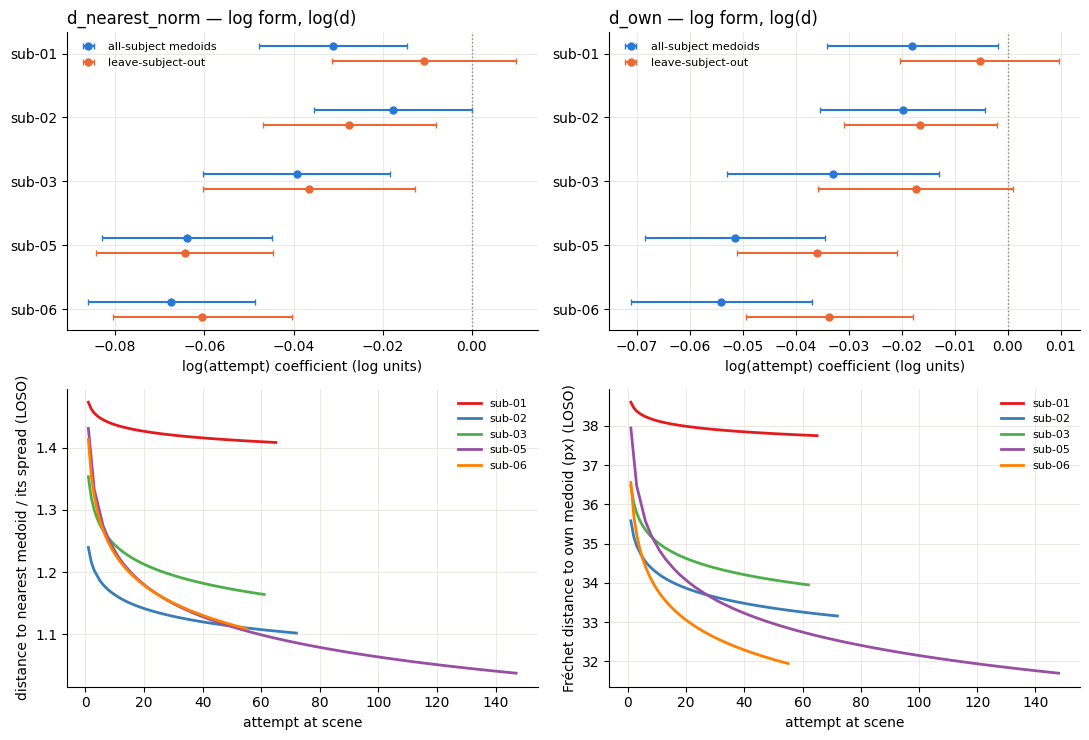

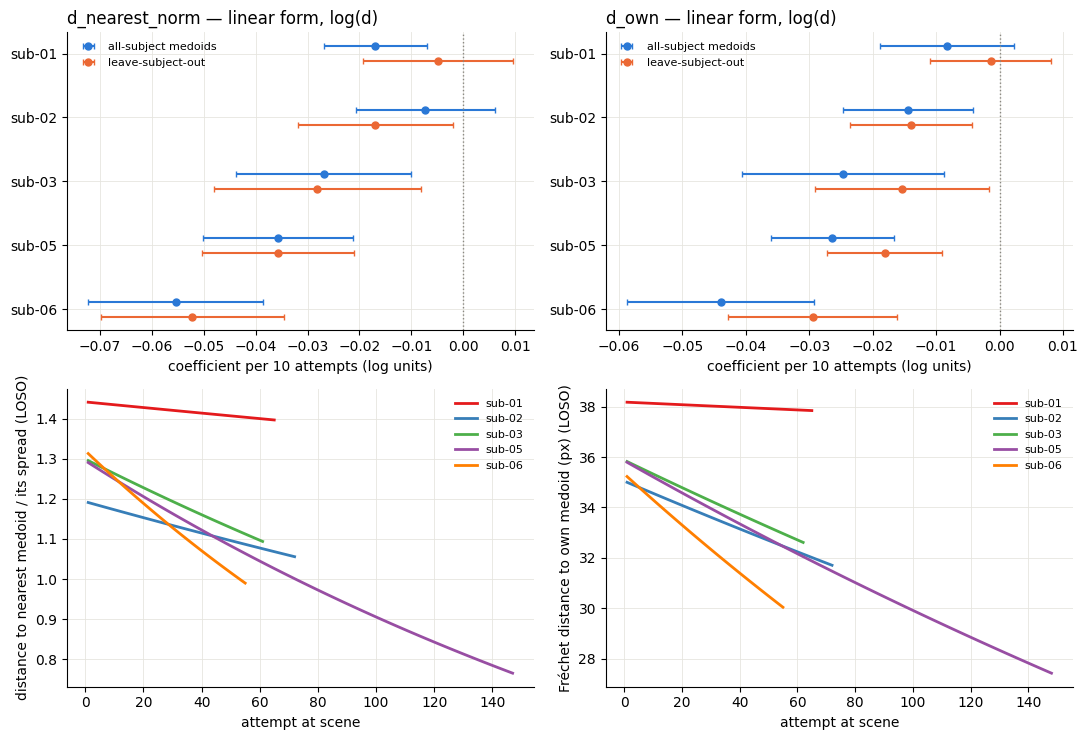

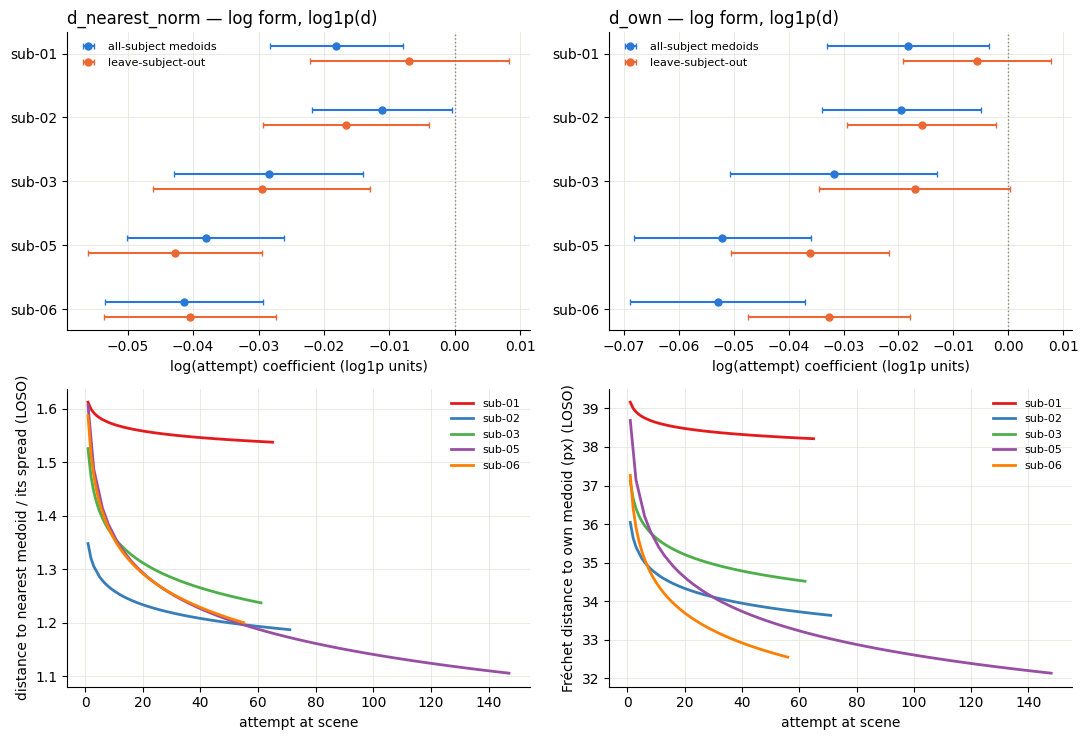

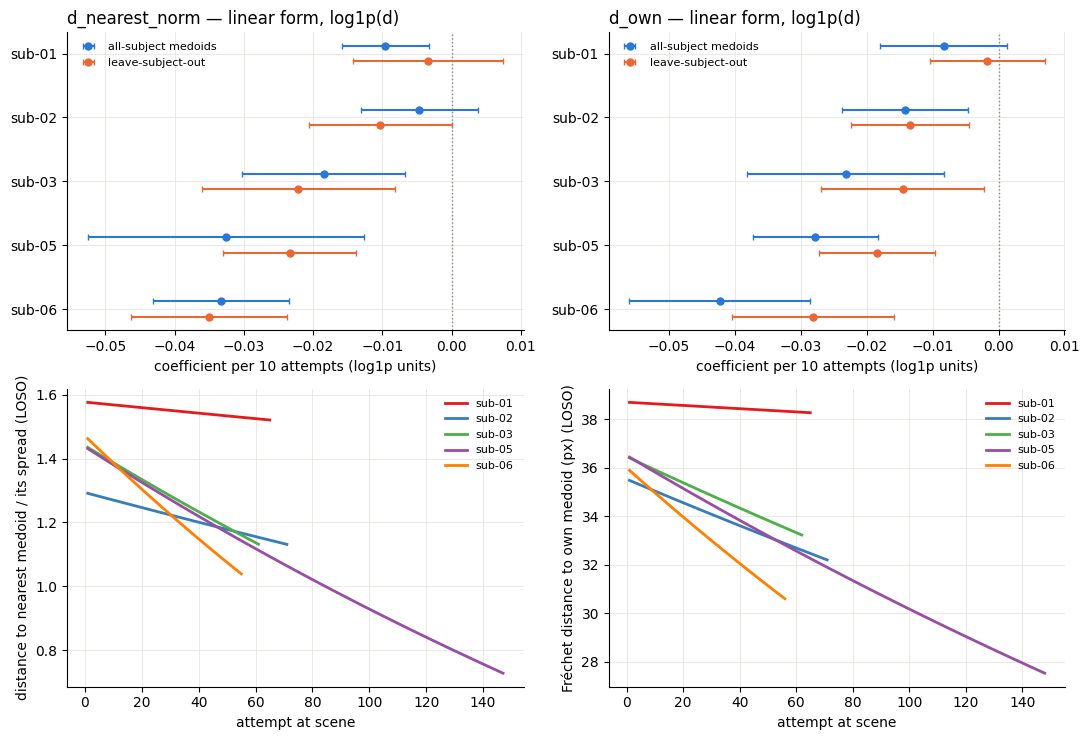

In [7]:
from analysis.practice import TRANSFORMS

PRIMARY_T = mixed["primary_transform"]
INVERSE = {k: v[1] for k, v in TRANSFORMS.items()}


def fits(measure, completed_only=False, transform=PRIMARY_T):
    return {f["subject"]: f for f in mixed["fits"]
            if f["measure"] == measure and f["completed_only"] == completed_only
            and f["transform"] == transform}


SLOPE = {"log": ("logt", "log(attempt) coefficient"),
         "linear": ("t", "coefficient per 10 attempts")}
measures = mixed["measures"]
subjects = mixed["subjects"]


def plot_mixed(form, path, transform=PRIMARY_T):
    term, xlabel = SLOPE[form]
    inv = INVERSE[transform]
    fig, axes = plt.subplots(2, len(measures), figsize=(5.5 * len(measures), 7.5), squeeze=False)
    for j, m in enumerate(measures):
        ax = axes[0, j]
        for off, (col, c, lbl) in zip((-0.12, 0.12), ((m, RAW, "all-subject medoids"),
                                                      (f"{m}_loso", LOSO, "leave-subject-out"))):
            per = fits(col, transform=transform)
            for i, s in enumerate(subjects):
                r = per.get(s, {}).get("forms", {}).get(form, {})
                if "coef" not in r:
                    continue
                b, (lo, hi) = r["coef"][term], r["ci"][term]
                ax.errorbar(b, i + off, xerr=[[b - lo], [hi - b]], fmt="o", color=c,
                            markersize=5, capsize=2, label=lbl if i == 0 else None)
        ax.axvline(0, color="#898781", linewidth=1, linestyle=":")
        ax.set_yticks(range(len(subjects)), [f"sub-{s}" for s in subjects])
        ax.invert_yaxis()
        ax.set_xlabel(f"{xlabel} ({transform} units)")
        ax.set_title(f"{m} — {form} form, {transform}(d)", loc="left")
        ax.legend(frameon=False, fontsize=8)

        ax = axes[1, j]
        for i, s in enumerate(subjects):
            r = fits(f"{m}_loso", transform=transform).get(s, {}).get("forms", {}).get(form, {})
            if "curve" not in r:
                continue
            ax.plot(r["curve"]["attempt"], inv(np.asarray(r["curve"]["y"])), color=SUBJECT_COLORS[i],
                    linewidth=2, label=f"sub-{s}")
        ax.set_xlabel("attempt at scene")
        ax.set_ylabel(UNITS[m] + " (LOSO)")
        ax.legend(frameon=False, fontsize=8)
    fig.tight_layout()
    fig.savefig(PRACTICE_DIR / path, dpi=150)


for transform in mixed["transforms"]:
    suffix = "" if transform == PRIMARY_T else f"_{transform}"
    plot_mixed("log", f"figure_practice_mixed{suffix}.png", transform)
    plot_mixed("linear", f"figure_practice_mixed_linear{suffix}.png", transform)

In [8]:
rows = []
for f in mixed["fits"]:
    for form in ("log", "log_phase"):
        r = f["forms"].get(form, {})
        if "coef" not in r:
            continue
        rows.append({"measure": f["measure"], "transform": f["transform"], "subject": f["subject"],
                     "completed_only": f["completed_only"], "form": form,
                     "coef_logt": r["coef"]["logt"], "ci_low": r["ci"]["logt"][0],
                     "ci_high": r["ci"]["logt"][1], "slope_sd": np.sqrt(r["re"].get("var_slope", np.nan)),
                     "best_form": f["best_form"], "n_obs": f["n_obs"],
                     "n_zero_dropped": f["n_zero_dropped"], "n_groups": f["n_groups"]})
table = pd.DataFrame(rows)
for transform in mixed["transforms"]:
    primary = table[(table["measure"] == mixed["primary"]) & (table["transform"] == transform)
                    & ~table["completed_only"] & (table["form"] == "log")]
    print(f"{mixed['primary']} [{transform}]: log(attempt) CI below zero for "
          f"{(primary['ci_high'] < 0).sum()} of {len(primary)} subjects")
table.round(4)

d_nearest_norm_loso [log]: log(attempt) CI below zero for 4 of 5 subjects
d_nearest_norm_loso [log1p]: log(attempt) CI below zero for 4 of 5 subjects


,measure,transform,subject,completed_only,form,coef_logt,ci_low,ci_high,slope_sd,best_form,n_obs,n_zero_dropped,n_groups
0,d_nearest_norm,log,01,False,log,-0.0312,-0.0478,-0.0146,0.0939,log,12590,48,290
1,d_nearest_norm,log,01,False,log_phase,-0.0387,-0.0620,-0.0154,0.0940,log,12590,48,290
2,d_nearest_norm,log,02,False,log,-0.0177,-0.0353,-0.0001,0.0928,log,10985,77,296
3,d_nearest_norm,log,02,False,log_phase,-0.0282,-0.0516,-0.0047,0.0928,log,10985,77,296
4,d_nearest_norm,log,03,False,log,-0.0393,-0.0603,-0.0183,0.1204,linear,9131,89,299
...,...,...,...,...,...,...,...,...,...,...,...,...,...
155,d_own_loso,log1p,03,True,log_phase,-0.0035,-0.0277,0.0206,0.1390,linear,8400,0,1053
156,d_own_loso,log1p,05,True,log,-0.0364,-0.0514,-0.0214,0.0802,quadratic,9969,0,1122
157,d_own_loso,log1p,05,True,log_phase,-0.0374,-0.0573,-0.0174,0.0803,quadratic,9969,0,1122
158,d_own_loso,log1p,06,True,log,-0.0335,-0.0481,-0.0190,0.0762,quadratic,8424,0,984


### Linear against log, per subject

The panels above draw every subject in the `log` form so the five are compared on one
shape — but that is a choice, not what each subject's data prefers. Here both forms
are drawn for the primary measure (`d_nearest_norm_loso`, all attempts), back-transformed
to the distance ratio, with the AIC difference in each title: **linear − log**, so a
positive number means log fits better and a negative one that linear does. Differences
under ~2 are a tie. Both curves are the *average scene* (scene adjustments set to 0),
drawn up to the subject's 95th-percentile attempt. Drawn per transform:
`figure_practice_forms.png` for `log`, `figure_practice_forms_log1p.png` for `log1p`.

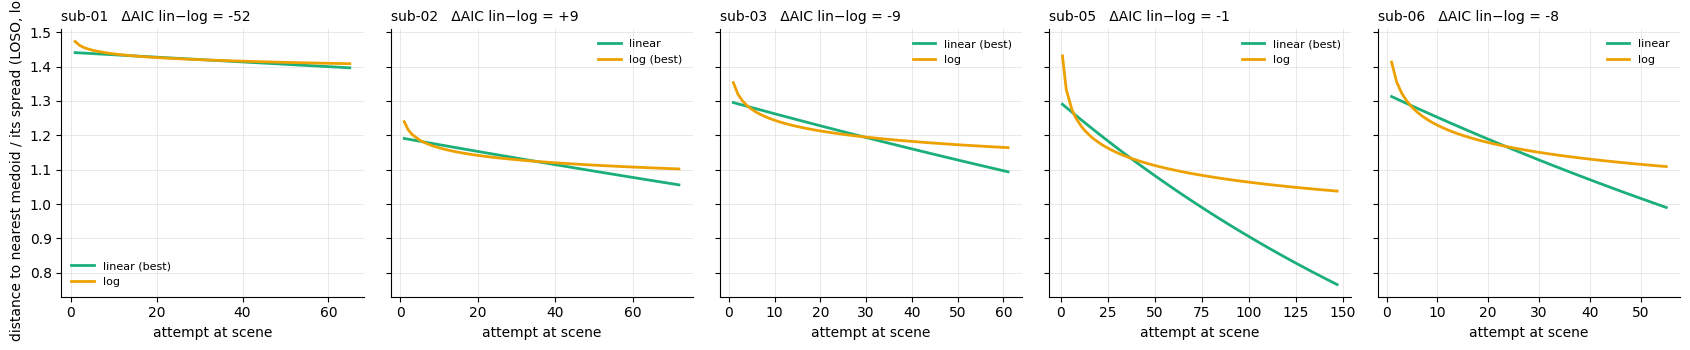

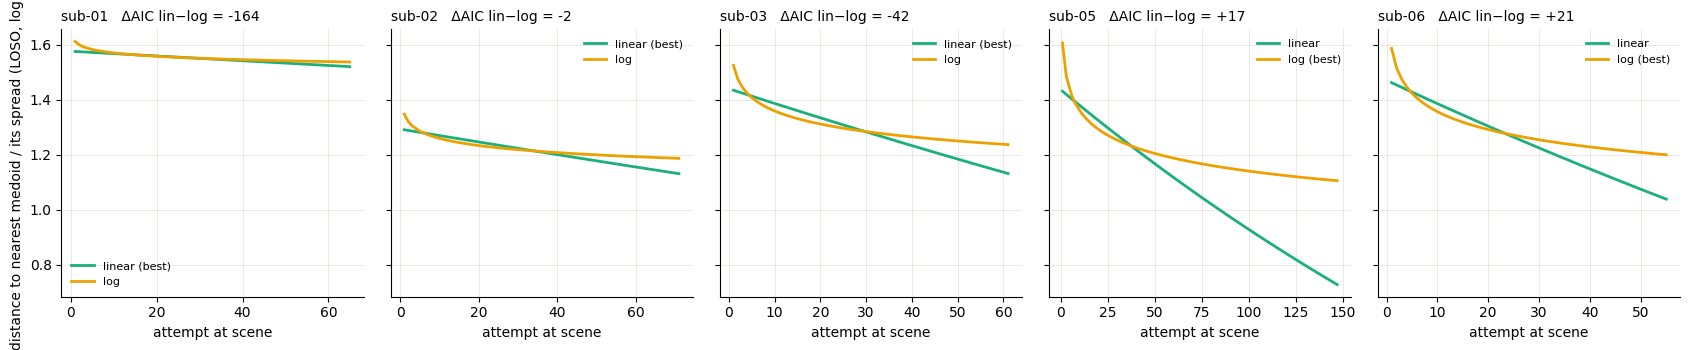

In [9]:
FORM_COLORS = {"linear": CLUSTER_COLORS[2], "log": CLUSTER_COLORS[3]}
for transform in mixed["transforms"]:
    per = fits(mixed["primary"], transform=transform)
    inv = INVERSE[transform]
    fig, axes = plt.subplots(1, len(subjects), figsize=(3.4 * len(subjects), 3.6), sharey=True)
    for ax, s in zip(np.atleast_1d(axes), subjects):
        forms = per[s]["forms"]
        for form, c in FORM_COLORS.items():
            r = forms.get(form, {})
            if "curve" not in r:
                continue
            ax.plot(r["curve"]["attempt"], inv(np.asarray(r["curve"]["y"])), color=c, linewidth=2,
                    label=f"{form}" + (" (best)" if per[s]["best_form"] == form else ""))
        diff = forms["linear"]["aic"] - forms["log"]["aic"]
        ax.set_title(f"sub-{s}   ΔAIC lin−log = {diff:+.0f}", loc="left", fontsize=10)
        ax.set_xlabel("attempt at scene")
        ax.legend(frameon=False, fontsize=8)
    np.atleast_1d(axes)[0].set_ylabel(UNITS["d_nearest_norm"] + f" (LOSO, {transform})")
    fig.tight_layout()
    suffix = "" if transform == PRIMARY_T else f"_{transform}"
    fig.savefig(PRACTICE_DIR / f"figure_practice_forms{suffix}.png", dpi=150)

### Random-effect structure: scenes nested in levels

The main model gives each scene a correlated random intercept and slope and assumes scenes
are independent — but a level's scenes are played back to back. Two alternatives are fitted
beside it, `log` form only, in `nested.json`: `level_scene` adds a random intercept and
slope per **level** with the scene effects nested inside, and `scene_uncorr` is the
scene-only model with the same restriction statsmodels imposes on nesting (no scene
intercept-slope correlation), so `level_scene` against `scene_uncorr` isolates what levels
add. Left: the practice slope with its 95% CI under each structure, for the primary
measure, all attempts. Right: the AIC difference against the main model — below zero fits
better. The main model keeps the scene correlation the nested one cannot have, so neither
alternative is a strict improvement on it; the model that has both needs lme4.

,transform,subject,structure,b,ci_low,ci_high,aic
0,log,01,scene,-0.0108,-0.0314,0.0099,25692.0487
1,log,02,scene,-0.0275,-0.0469,-0.0080,21926.0965
2,log,03,scene,-0.0366,-0.0604,-0.0129,19734.0593
3,log,05,scene,-0.0644,-0.0842,-0.0446,24641.9583
4,log,06,scene,-0.0604,-0.0804,-0.0404,18424.7539
5,log,01,scene_uncorr,-0.0095,-0.0261,0.0072,25781.6608
6,log,02,scene_uncorr,-0.0258,-0.0410,-0.0106,21970.8983
7,log,03,scene_uncorr,-0.0369,-0.0546,-0.0192,19849.7567
8,log,05,scene_uncorr,-0.0580,-0.0747,-0.0412,24680.8544
9,log,06,scene_uncorr,-0.0574,-0.0747,-0.0401,18453.1437


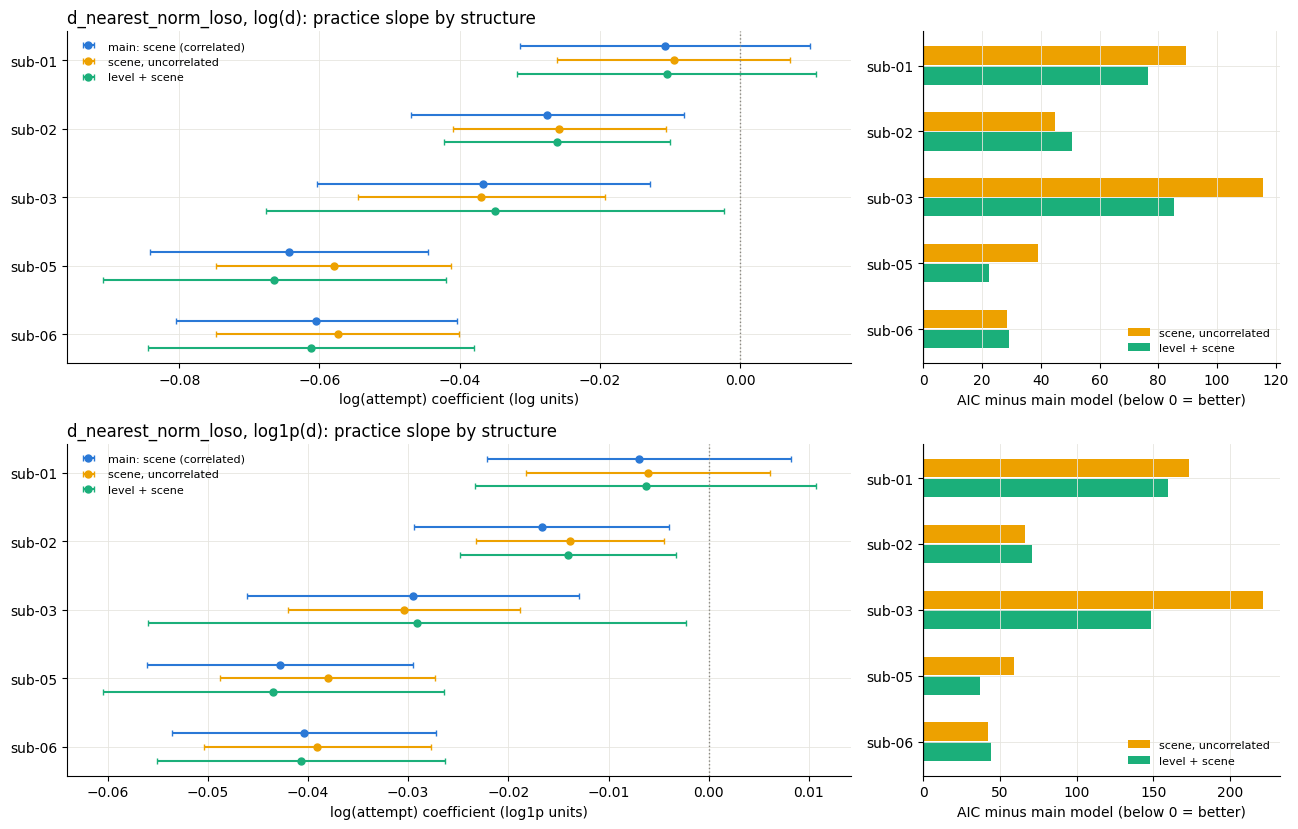

In [10]:
nested = json.loads((PRACTICE_DIR / "nested.json").read_text())
STRUCT = {"scene": ("main: scene (correlated)", CLUSTER_COLORS[0]),
          "scene_uncorr": ("scene, uncorrelated", CLUSTER_COLORS[3]),
          "level_scene": ("level + scene", CLUSTER_COLORS[2])}


def structure_fits(transform):
    out = {("scene", s): f["forms"]["log"] for s, f in fits(mixed["primary"], transform=transform).items()}
    for f in nested["fits"]:
        if (f["measure"] == mixed["primary"] and f["transform"] == transform
                and not f["completed_only"] and "coef" in f):
            out[(f["structure"], f["subject"])] = f
    return out


fig, axes = plt.subplots(len(mixed["transforms"]), 2, figsize=(13, 4.2 * len(mixed["transforms"])),
                         squeeze=False, gridspec_kw={"width_ratios": [2.2, 1]})
rows = []
for k, transform in enumerate(mixed["transforms"]):
    sf = structure_fits(transform)
    ax, axa = axes[k]
    for off, st in zip((-0.2, 0, 0.2), STRUCT):
        label, c = STRUCT[st]
        for i, s in enumerate(subjects):
            r = sf.get((st, s))
            if r is None:
                continue
            b, (lo, hi) = r["coef"]["logt"], r["ci"]["logt"]
            ax.errorbar(b, i + off, xerr=[[b - lo], [hi - b]], fmt="o", color=c, ms=5, capsize=2,
                        label=label if i == 0 else None)
            rows.append({"transform": transform, "subject": s, "structure": st, "b": b,
                         "ci_low": lo, "ci_high": hi, "aic": r["aic"]})
    ax.axvline(0, color="#898781", lw=1, ls=":")
    ax.set_yticks(range(len(subjects)), [f"sub-{s}" for s in subjects])
    ax.invert_yaxis()
    ax.set_xlabel(f"log(attempt) coefficient ({transform} units)")
    ax.set_title(f"{mixed['primary']}, {transform}(d): practice slope by structure", loc="left")
    ax.legend(frameon=False, fontsize=8)
    t = pd.DataFrame([r for r in rows if r["transform"] == transform])
    a = t.pivot(index="subject", columns="structure", values="aic").loc[subjects]
    for off, st in zip((-0.15, 0.15), ("scene_uncorr", "level_scene")):
        axa.barh(np.arange(len(subjects)) + off, a[st] - a["scene"], height=0.28,
                 color=STRUCT[st][1], label=STRUCT[st][0])
    axa.axvline(0, color="k", lw=0.8)
    axa.set_yticks(range(len(subjects)), [f"sub-{s}" for s in subjects])
    axa.invert_yaxis()
    axa.set_xlabel("AIC minus main model (below 0 = better)")
    axa.legend(frameon=False, fontsize=8)
fig.tight_layout()
fig.savefig(PRACTICE_DIR / "figure_practice_structures.png", dpi=150)
pd.DataFrame(rows).round(4)

## 3. Which curve shape, series by series

For every series with ≥ 10 attempts: which of linear / quadratic / power / exponential
has the lowest AICc, and whether the best curve ends lower than it started. The
`change` column is in transformed units, so it is comparable across curve shapes.
Drawn for the primary transform; `curves.csv` holds both.

series  median_n   fell  median_change
transform measure                                                    
log       d_nearest_norm         1403      32.0  0.612         -0.123
          d_nearest_norm_loso    1411      33.0  0.605         -0.108
          d_own                  1584      18.0  0.559         -0.064
          d_own_loso             1603      18.0  0.524         -0.024
log1p     d_nearest_norm         1403      32.0  0.629         -0.073
          d_nearest_norm_loso    1411      34.0  0.619         -0.067
          d_own                  1598      18.0  0.566         -0.066
          d_own_loso             1615      18.0  0.533         -0.030

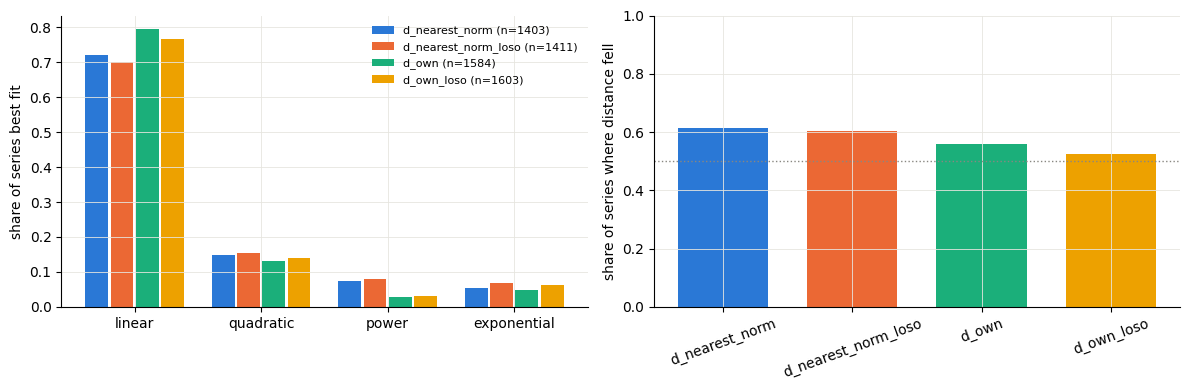

In [11]:
models = ["linear", "quadratic", "power", "exponential"]
measure_cols = [c for m in measures for c in (m, f"{m}_loso")]
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
width = 0.8 / len(measure_cols)
palette = CLUSTER_COLORS[:len(measure_cols)]
for i, (col, c) in enumerate(zip(measure_cols, palette)):
    sub = curves[(curves["measure"] == col) & (curves["transform"] == PRIMARY_T)]
    share = sub["best"].value_counts(normalize=True).reindex(models, fill_value=0)
    axes[0].bar(np.arange(len(models)) + (i - (len(measure_cols) - 1) / 2) * width, share,
                width=width * 0.9, color=c, label=f"{col} (n={len(sub)})")
    axes[1].bar(i, (sub["change"] < 0).mean(), color=c, width=0.7)
axes[0].set_xticks(range(len(models)), models)
axes[0].set_ylabel("share of series best fit")
axes[0].legend(frameon=False, fontsize=8)
axes[1].set_xticks(range(len(measure_cols)), measure_cols, rotation=20)
axes[1].axhline(0.5, color="#898781", linestyle=":", linewidth=1)
axes[1].set_ylabel("share of series where distance fell")
axes[1].set_ylim(0, 1)
fig.tight_layout()
fig.savefig(PRACTICE_DIR / "figure_practice_curves.png", dpi=150)
curves.groupby(["transform", "measure"]).agg(series=("n", "size"), median_n=("n", "median"),
                              fell=("change", lambda x: (x < 0).mean()),
                              median_change=("change", "median")).round(3)

## 4. Does strategy choice settle?

Share of attempts using a different cluster than the subject's previous attempt at the
same scene, pooled over scenes in bins of attempts. The trend is a logistic GLM on
`log(attempt)` with errors clustered by subject × scene.

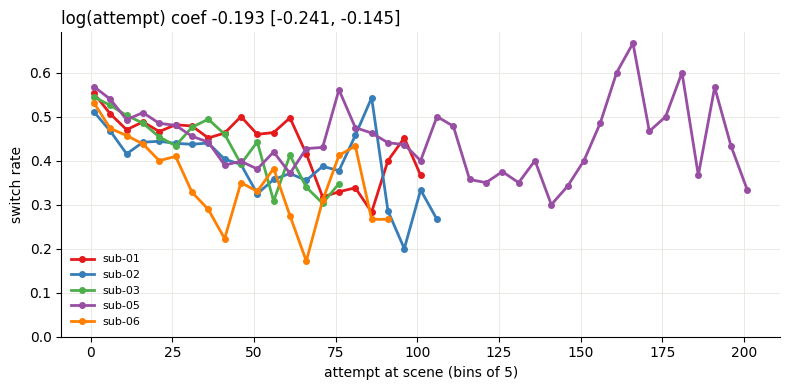

In [12]:
b = pd.DataFrame(switching["binned"])
b = b[b["n"] >= 30]
fig, ax = plt.subplots(figsize=(8, 4))
for i, (subj, g) in enumerate(b.groupby("subject")):
    ax.plot(g["bin"], g["rate"], color=SUBJECT_COLORS[i], linewidth=2, marker="o", markersize=4,
            label=f"sub-{subj}")
ax.set_xlabel(f"attempt at scene (bins of {switching['bin_width']})")
ax.set_ylabel("switch rate")
ax.set_ylim(0, None)
ax.legend(frameon=False, fontsize=8)
t = switching["trend"]
ax.set_title(f"log(attempt) coef {t['coef_logt']:.3f} [{t['ci'][0]:.3f}, {t['ci'][1]:.3f}]", loc="left")
fig.tight_layout()
fig.savefig(PRACTICE_DIR / "figure_practice_switching.png", dpi=150)